# U-Net - segmentacja obrazów (Carvana)
**Autorzy:** Kornelia Kołodziejska, Michał Bibrzycki, Wiktoria Jeleniewicz

**Przedmiot:** Analiza danych obrazowych i multimedialnych

Notebook zawiera implementację sieci **U-Net** opisanej w pracy:

> O. Ronneberger, P. Fischer, T. Brox, *U-Net: Convolutional Networks for Biomedical Image Segmentation*, MICCAI 2015 (arXiv:1505.04597).

Zakres implementacji:

- fragment wejściowy **572×572**, maska wyjściowa **388×388**,
- sploty **3×3 bez paddingu** w blokach `DoubleConv`, up-conv 2×2 i splot 1×1 na wyjściu,
- ścieżka zmniejszająca i symetryczna ścieżka rozszerzająca z połączeniami pomijającymi,
- ważona strata: rzadsza klasa oraz piksele przy granicach obiektów mają większy wpływ,
- strategia **overlap-tile** przy predykcji dużych obrazów.

Dane: **Carvana Image Masking Challenge** - 5088 zdjęć samochodów (RGB, 1918×1280) i binarne maski karoserii.

## Biblioteki i wersje

Notebook uruchamiano na **Pythonie 3.12.6**.

| Biblioteka | Wersja | Zastosowanie |
|---|---|---|
| `torch` | 2.9.1+cu126 | sieć, trening, tensory |
| `torchvision` | 0.24.1+cu126 | przycinanie map cech (`center_crop`) i augmentacja (`ElasticTransform`) |
| `numpy` | 2.5.4 | praca na obrazach i maskach |
| `Pillow` | 12.3.0 | wczytywanie JPEG/GIF |
| `matplotlib` | 3.9.3 | wizualizacje |
| `scipy` | 1.18.1 | mapa wag (`distance_transform_edt`) |
| `tqdm` | 4.67.1 | pasek postępu |
| `jupyterlab` | 4.5.0 | uruchomienie notebooka |

Przed uruchomieniem notebooka wymagana jest instalacja bibliotek w terminalu. Instalacja z GPU (CUDA 12.6):

```bash
pip install torch==2.9.1 torchvision==0.24.1 --index-url https://download.pytorch.org/whl/cu126
pip install numpy==2.5.4 Pillow==12.3.0 matplotlib==3.9.3 scipy==1.18.1 tqdm==4.67.1 jupyterlab==4.5.0
```

Wersja CPU wymaga pominięcia `--index-url` (lub użycia indeksu CPU PyTorch). Przy innej wersji CUDA należy dobrać odpowiedni indeks ze strony PyTorch.

## Konfiguracja

### Rozmiary

| Parametr | Wartość | Znaczenie |
|---|---|---|
| `INPUT_SIZE` | 572 | wymiar kwadratowego fragmentu obrazu wejściowego |
| `OUTPUT_SIZE` | 388 | wymiar kwadratowej maski wyjściowej |
| `CONTEXT` | 92 | kontekst z każdej strony, `(572 - 388) // 2` |

`CONTEXT` jest wyliczany, a nie wpisany ręcznie, żeby nie rozjechał się przy zmianie rozmiarów.

Ponieważ sieć wykorzystuje sploty bez paddingu, mapy cech stopniowo zmniejszają swoje wymiary, a maska wyjściowa obejmuje jedynie centralną część obrazu wejściowego. Dodatkowe 92 piksele z każdej strony dostarczają kontekstu z otoczenia segmentowanego obszaru, dzięki czemu sieć może uwzględniać sąsiednie informacje podczas predykcji.

Podczas segmentacji całego obrazu jest on przetwarzany w kafelkach. Dla każdego obszaru wynikowego o wymiarach 388×388 pobierany jest większy fragment wejściowy 572×572, zawierający również wymagany kontekst. Sąsiednie fragmenty wejściowe nakładają się na siebie, natomiast odpowiadające im obszary wyjściowe tworzą całą maskę.

### Trening

| Parametr | Znaczenie |
|---|---|
| `EPOCHS` | liczba epok |
| `BATCH_SIZE` | liczba obrazów w jednym kroku |
| `MOMENTUM` | momentum optymalizatora SGD |
| `LEARNING_RATE` | współczynnik uczenia |
| `DROPOUT` | `p` w `Dropout2d` |
| `SEED` | ziarno losowości |

### Ograniczenie zbioru

`TRAIN_SAMPLES` i `VAL_SAMPLES` działają jak limit, a nie jak liczba próbek:

- `None` - użyj wszystkiego: 4579 obrazów treningowych i 509 walidacyjnych,
- liczba - użyj tylko pierwszych `n` pozycji z listy.

Szybki przebieg kontrolny: `EPOCHS = 10`, `TRAIN_SAMPLES = 8`, `VAL_SAMPLES = 2`.

`DEVICE` jest wybierany automatycznie: `cuda`, jeśli karta jest dostępna, w przeciwnym razie `cpu`.

In [ ]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from scipy.ndimage import distance_transform_edt
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2
from torchvision.transforms.functional import center_crop
from torchvision.tv_tensors import Image as TVImage
from torchvision.tv_tensors import Mask as TVMask
from tqdm import tqdm

BASE_DIR = Path.cwd()
if not (BASE_DIR / "data" / "imgs").exists():
    BASE_DIR = BASE_DIR / "U-Net"

DATA_DIR = BASE_DIR / "data"
IMAGES_DIR = DATA_DIR / "imgs"
MASKS_DIR = DATA_DIR / "masks"
TEST_DIR = DATA_DIR / "test"
CHECKPOINT_PATH = BASE_DIR / "unet_carvana.pth"

# Wymiar wejścia do kodera 572x572
INPUT_SIZE = 572
# Wymiar maski wyjściowej 388x388
OUTPUT_SIZE = 388
# Rozmiar dodatkowego kontekstu
CONTEXT = (INPUT_SIZE - OUTPUT_SIZE) // 2
N_CLASSES = 2
EPOCHS = 10
BATCH_SIZE = 1
LEARNING_RATE = 1e-4
MOMENTUM = 0.99
DROPOUT = 0.2
# Ograniczenie ilości próbek treningowych
TRAIN_SAMPLES = None
# Ograniczenie ilości próbek walidacyjnych
VAL_SAMPLES = None
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Urządzenie: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Urządzenie: cuda
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


## Dane

Zbiór Carvana zawiera zdjęcia samochodów oraz binarne maski: `0` oznacza tło, `1` - karoserię.

Pliki znajdują się w `data/imgs` i `data/masks`. Maski mają rozszerzenie `.gif` i są wczytywane jako obrazy w skali szarości.

Dane można pobrać z Kaggle: <https://www.kaggle.com/c/carvana-image-masking-challenge/data>. Oczekiwana struktura katalogów:

```text
data/
  imgs/   *.jpg
  masks/  *_mask.gif
```

Zbiór jest dzielony na treningowy i walidacyjny w proporcji 9:1. Sposób podziału odwzorowuje `random_split` i domyślne `--validation 10` z repozytorium `Pytorch-UNet`.

Podział losowy po zdjęciach może sprawić, że różne ujęcia tego samego auta trafią do obu zbiorów, co nazywamy przeciekiem. W testach kontrolnych nie zaobserwowano jednak wyraźnych zmian wyników. Podział jest powtarzalny dzięki `SEED = 42`.

Przy 5088 obrazach otrzymywane jest około **4579 obrazów treningowych i 509 walidacyjnych**. `TRAIN_SAMPLES = None` oznacza użycie wszystkich obrazów treningowych, a `VAL_SAMPLES = None` pełną walidację, wartość liczbowa skraca ją w trakcie epoki.

In [2]:
assert IMAGES_DIR.exists(), f"Brak katalogu {IMAGES_DIR}"
assert MASKS_DIR.exists(), f"Brak katalogu {MASKS_DIR}"

image_ids = sorted(path.stem for path in IMAGES_DIR.glob("*.jpg"))
random.Random(SEED).shuffle(image_ids)
split_index = int(0.9 * len(image_ids))
train_ids = image_ids[:split_index]
val_ids = image_ids[split_index:]
if TRAIN_SAMPLES is not None:
    train_ids = train_ids[:TRAIN_SAMPLES]
if VAL_SAMPLES is not None:
    val_ids = val_ids[:VAL_SAMPLES]
assert TRAIN_SAMPLES != 0, "TRAIN_SAMPLES nie może być 0"
assert VAL_SAMPLES != 0, "VAL_SAMPLES nie może być 0"
print(f"Trening: {len(train_ids)} obrazów, walidacja: {len(val_ids)} obrazów")

Trening: 4579 obrazów, walidacja: 509 obrazów


### Przykład danych

Zdjęcie jest kolorowe i ma trzy kanały (RGB), a maska jest czarno-biała i ma jeden. Po wczytaniu w trybie `L` maska przyjmuje wartości `0` i `255`. W datasetcie zamieniamy je na `0` (tło) i `1` (karoseria), bo takich etykiet wymaga funkcja straty. Robimy to prostym porównaniem `> 0`.

Maska ma dokładnie ten sam rozmiar co zdjęcie, więc sieć przewiduje ją piksel po pikselu, bez skalowania. Poniżej przykładowa para: zdjęcie i odpowiadająca mu maska.

Obraz: (1918, 1280), maska: (1918, 1280)
Wartości maski: [  0 255]


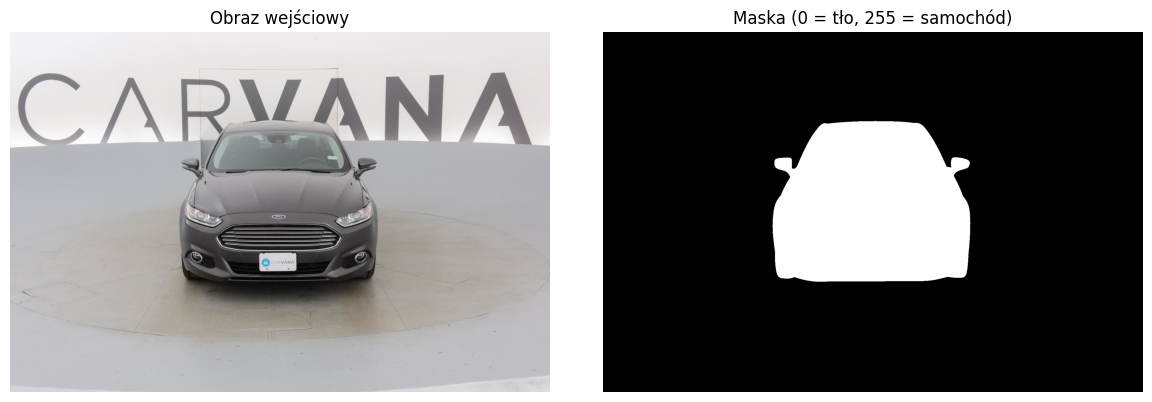

In [3]:
sample_id = train_ids[0]
sample_image = Image.open(IMAGES_DIR / f"{sample_id}.jpg").convert("RGB")
sample_mask = Image.open(MASKS_DIR / f"{sample_id}_mask.gif").convert("L")
print(f"Obraz: {sample_image.size}, maska: {sample_mask.size}")
print(f"Wartości maski: {np.unique(np.array(sample_mask))}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(sample_image)
axes[0].set_title("Obraz wejściowy")
axes[0].axis("off")
axes[1].imshow(sample_mask, cmap="gray")
axes[1].set_title("Maska (0 = tło, 255 = samochód)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

## Przygotowanie fragmentów danych

Sieć nie widzi całego zdjęcia, tylko wycinek 572×572. Dlatego z każdego obrazu losujemy fragment w dwóch krokach:

1. wybieramy **region wyjściowy 388×388** - to część maski, którą chcemy przewidzieć,
2. dokładamy wokół niego **92 piksele kontekstu** z każdej strony, żeby sieć wiedziała, co jest dookoła.

Po dodaniu kontekstu powstaje wejście 572×572, a sieć zwraca maskę 388×388. (92 + 388 + 92 = 572)

Przy brzegach zdjęcia brakujące piksele uzupełniamy odbiciem lustrzanym (`reflect`), żeby nie wstawiać czerni, której w zdjęciu nie ma.

Zanim obraz trafi do sieci, jest jeszcze augmentowany. Stosujemy deformację elastyczną (`ElasticTransform(alpha=50, sigma=5)`) i losowe odbicie poziome. Obie transformacje działają równocześnie na zdjęciu i masce, więc etykiety zostają spójne.

Na koniec piksele dzielimy przez `255`, czyli sprowadzamy je do zakresu 0-1. Normalizacji ImageNet nie używamy, bo model uczymy od zera.

Dataset zwraca trzy rzeczy: obraz 572×572, maskę docelową 388×388 i maskę kontekstową 572×572. Maska kontekstowa jest potrzebna, żeby policzyć mapę wag z pełnym otoczeniem, a potem przycina się ją do 388×388. Walidacja odbywa się na całych zdjęciach, więc nie trzeba przygotowywać osobnego zbioru kafelków.

In [4]:
class CarvanaDataset(Dataset):
    def __init__(self, image_ids):
        self.image_ids = image_ids
        self.augmentation = v2.Compose([
            v2.ElasticTransform(alpha=50.0, sigma=5.0),
            v2.RandomHorizontalFlip(p=0.5),
        ])

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        image = np.array(Image.open(IMAGES_DIR / f"{image_id}.jpg").convert("RGB"))
        mask = (np.array(Image.open(MASKS_DIR / f"{image_id}_mask.gif").convert("L")) > 0).astype(np.int64)
        assert image.shape[:2] == mask.shape[:2], "Obraz i maska muszą mieć ten sam rozmiar"
        image = np.pad(image, ((CONTEXT, CONTEXT), (CONTEXT, CONTEXT), (0, 0)), mode="reflect")
        mask = np.pad(mask, ((CONTEXT, CONTEXT), (CONTEXT, CONTEXT)), mode="reflect")

        max_top = mask.shape[0] - INPUT_SIZE
        max_left = mask.shape[1] - INPUT_SIZE
        top = np.random.randint(0, max_top + 1)
        left = np.random.randint(0, max_left + 1)

        image_tile = image[top:top + INPUT_SIZE, left:left + INPUT_SIZE]
        mask_tile = mask[top:top + INPUT_SIZE, left:left + INPUT_SIZE]

        image_tile = TVImage(torch.from_numpy(image_tile.copy()).permute(2, 0, 1).contiguous())
        mask_tile = TVMask(torch.from_numpy(mask_tile.copy()))
        image_tile, mask_tile = self.augmentation(image_tile, mask_tile)

        image_tile = image_tile.float() / 255.0
        mask_context = mask_tile.long()
        mask_tile = mask_context[CONTEXT:CONTEXT + OUTPUT_SIZE, CONTEXT:CONTEXT + OUTPUT_SIZE]
        return image_tile, mask_tile, mask_context

### DataLoader

`DataLoader` bierze dataset i podaje go w porcjach (batchach) podczas treningu. Domyślnie miesza kolejność, więc każda epoka widzi zdjęcia w innej kolejności.

Batch wynosi 1.

In [5]:
train_dataset = CarvanaDataset(train_ids)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)
sample_images, sample_masks, sample_context_masks = next(iter(train_loader))
print(f"Batch obrazów: {sample_images.shape}")
print(f"Batch masek docelowych: {sample_masks.shape}")
print(f"Batch masek kontekstowych: {sample_context_masks.shape}")

Batch obrazów: torch.Size([1, 3, 572, 572])
Batch masek docelowych: torch.Size([1, 388, 388])
Batch masek kontekstowych: torch.Size([1, 572, 572])


## Architektura U-Net

U-Net to dwie symetryczne części: najpierw obraz jest zmniejszany, a potem odtwarzany z powrotem do rozmiaru maski.

1. **Ścieżka kurcząca (coder)** - powtarzamy dwa sploty 3×3 z ReLU, a po nich max-pooling 2×2. Po każdym poolingu liczba kanałów podwaja się: 64 → 128 → 256 → 512 → 1024. Sploty nie mają paddingu, więc obraz przy okazji się zmniejsza.
2. **Ścieżka rozszerzająca (decoder)** - splot transponowany 2×2 (`up-conv`) podwaja rozdzielczość i zmniejsza liczbę kanałów. Mapa cech z codera jest przycinana do rozmiaru dekodera i **sklejana** z jego mapą (skip connection). Na koniec dwa sploty 3×3 z ReLU.
3. **Wyjście** - splot 1×1 zamienia 64 kanały na 2 klasy: tło i samochód.

Skip connections są tu kluczowe. Coder wie, *co* jest na obrazie, ale po drodze gubi *gdzie* dokładnie. Decoder odtwarza kształt, ale bez skip connections zgubiłby ostre granice. Połączenie obu daje i kontekst, i dokładny kontur.

Łącznie mamy 23 warstwy splotowe: **18 splotów 3×3, 4 up-conv 2×2 i 1 splot 1×1**.

BatchNorm nie jest używany. Biblioteka `Pytorch-UNet` go stosuje, ale tutaj go nie ma, żeby zachować zgodność z artykułem. Na końcu codera działa `Dropout2d(p=0.2)`. Wagi są inicjalizowane metodą He (Kaiming), dopasowaną do ReLU.

W klasie `Up` parametr `in_channels` oznacza liczbę kanałów przed up-conv. Po podziale przez 2 i sklejeniu ze skip connection do dwóch splotów trafia dokładnie `in_channels` kanałów.

In [6]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=0),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=0),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class Down(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.MaxPool2d(kernel_size=2),
            DoubleConv(in_channels, out_channels),
        )

    def forward(self, x):
        return self.layers(x)


class Up(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        skip = center_crop(skip, x.shape[-2:])
        return self.conv(torch.cat([skip, x], dim=1))


class UNet(nn.Module):
    def __init__(self, in_channels=3, n_classes=2, dropout=0.2):
        super().__init__()
        self.inc = DoubleConv(in_channels, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)
        self.down4 = Down(512, 1024)
        self.dropout = nn.Dropout2d(p=dropout)
        self.up1 = Up(1024, 512)
        self.up2 = Up(512, 256)
        self.up3 = Up(256, 128)
        self.up4 = Up(128, 64)
        self.outc = nn.Conv2d(64, n_classes, kernel_size=1, padding=0)
        self._initialize_weights()

    def _initialize_weights(self):
        for module in self.modules():
            if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(module.weight, nonlinearity="relu")
                if module.bias is not None:
                    nn.init.zeros_(module.bias)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.dropout(self.down4(x4))
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        return self.outc(x)

### Sprawdzenie architektury

Każdy splot 3×3 bez paddingu zmniejsza obraz o 2 piksele, a para splotów o 4. Pooling dzieli rozmiar przez 2. Dla wejścia 572×572 wygląda to tak:

| Etap | Operacja | Rozmiar |
|---|---|---|
| wejście | - | 572 |
| `inc` | 2× conv 3×3 | 568 |
| `down1` | pool + 2× conv | 280 |
| `down2` | pool + 2× conv | 136 |
| `down3` | pool + 2× conv | 64 |
| `down4` | pool + 2× conv | 28 |
| `up1` | up-conv + crop + 2× conv | 52 |
| `up2` | up-conv + crop + 2× conv | 100 |
| `up3` | up-conv + crop + 2× conv | 196 |
| `up4` | up-conv + crop + 2× conv | 388 |


Łącznie z 572 robi się 388, czyli ginie 184 piksele - po 92 z każdej strony. Dlatego `CONTEXT = (572 - 388) // 2 = 92`.

Jest jeszcze jeden warunek: przed każdym poolingiem rozmiar musi być parzysty. Wartości 568, 280, 136 i 64 są parzyste, więc 572 pasuje. Dla 570 już by nie zadziałało.

Test poniżej sprawdza kształt wyjścia i liczbę parametrów.

In [7]:
model = UNet(in_channels=3, n_classes=N_CLASSES, dropout=DROPOUT).to(DEVICE)
dummy_input = torch.zeros(1, 3, INPUT_SIZE, INPUT_SIZE, device=DEVICE)
with torch.no_grad():
    dummy_output = model(dummy_input)
parameter_count = sum(parameter.numel() for parameter in model.parameters())
assert tuple(dummy_output.shape) == (1, N_CLASSES, OUTPUT_SIZE, OUTPUT_SIZE)
print(f"Wyjście: {tuple(dummy_output.shape)}")
print(f"Parametry: {parameter_count:,}")

Wyjście: (1, 2, 388, 388)
Parametry: 31,031,810


## Funkcja straty

Sieć zwraca dla każdego piksela dwie liczby: wynik dla tła i dla samochodu. Softmax zamienia je na prawdopodobieństwa, które sumują się do 1.

Zastosowana strata to **ważona entropia krzyżowa**:

$$E = -\frac{1}{|\Omega|}\sum_{x \in \Omega} w(x) \log p_{\ell(x)}(x)$$

W praktyce wygląda to tak: dla każdego piksela bierzemy prawdopodobieństwo klasy poprawnej, liczymy z niego `-log`, mnożymy przez wagę `w(x)` i uśredniamy po wszystkich pikselach. Im pewniejsza i poprawna predykcja, tym mniejsza strata.

Waga `w(x)` składa się z dwóch części:

- **waga klasy** - klasa rzadsza, czyli samochód, dostaje większą wagę niż tło. Liczymy ją z próbki 100 masek treningowych.
- **waga brzegu** - zwiększa znaczenie pikseli znajdujących się w pobliżu granicy samochodu i tła. Jest wyznaczana na podstawie sumy odległości do najbliższych pikseli należących do przeciwnych klas. Wartość dodatkowej wagi maleje wraz z oddalaniem się od granicy. Parametr `w0 = 10` określa jej maksymalną siłę, a `sigma = 5` wpływa na tempo zanikania.

Mapę wag liczymy na masce kontekstowej 572×572, a potem przycinamy do 388×388. Dzięki temu krawędź wycinka nie zniekształca odległości do granicy.

In [8]:
weight_sample_ids = random.Random(SEED + 3).sample(train_ids, min(100, len(train_ids)))
sample_masks = [
    np.array(Image.open(MASKS_DIR / f"{image_id}_mask.gif").convert("L")) > 0
    for image_id in weight_sample_ids
]
foreground_fraction = float(np.mean([mask.mean() for mask in sample_masks]))
class_weights = torch.tensor(
    [1.0 / (2.0 * (1.0 - foreground_fraction)), 1.0 / (2.0 * foreground_fraction)],
    dtype=torch.float32,
)
print(f"Udział samochodu: {foreground_fraction:.3f}")
print(f"Wagi klas: {class_weights.tolist()}")

Udział samochodu: 0.207
Wagi klas: [0.6305356025695801, 2.4151859283447266]


### Mapa wag

Dla każdego piksela liczymy odległość do najbliższej granicy obiektu. Ta odległość steruje wagą: blisko konturu rośnie (nawet o `w0 = 10`), a daleko od niego jest mała. Dzięki temu strata mocniej karze błędy na obrysie samochodu, bo tam pomyłka jest najbardziej widoczna.

Funkcja `weighted_cross_entropy` dostaje maski kontekstowe 572×572, a nie docelowe 388×388. To ważne: gdybyśmy liczyli odległości tylko na wycinku, piksele przy jego krawędzi sądziłyby, że granica obiektu jest tuż obok. Przycięcie do 388×388 robimy dopiero po policzeniu odległości, w tym samym miejscu, w którym przycinamy maskę.

In [9]:
def make_weight_map(mask, class_weights, w0=10.0, sigma=5.0):
    foreground = mask.bool().numpy()
    if not foreground.any():
        return class_weights[mask]
    distance_to_foreground = distance_transform_edt(~foreground)
    distance_to_background = distance_transform_edt(foreground)
    border_weight = np.exp(
        -((distance_to_foreground + distance_to_background) ** 2) / (2.0 * sigma ** 2)
    )
    return class_weights[mask] + w0 * torch.from_numpy(border_weight).float()


def weighted_cross_entropy(logits, target, context_masks, class_weights, w0=10.0, sigma=5.0):
    weights = []
    for context_mask in context_masks:
        weight = make_weight_map(context_mask.cpu(), class_weights.cpu(), w0, sigma)
        weights.append(weight[CONTEXT:CONTEXT + OUTPUT_SIZE, CONTEXT:CONTEXT + OUTPUT_SIZE])
    weights = torch.stack(weights).to(logits.device)
    loss = F.cross_entropy(logits, target, reduction="none")
    return (loss * weights).mean()

## Optymalizator

Używamy **SGD z momentum 0.99**. Momentum sprawia, że aktualizacja zależy nie tylko od bieżącego gradientu, ale też od poprzednich kroków. Przy batchu 1 trening jest dzięki temu dużo stabilniejszy.

In [10]:
optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM)

## Miara jakości: Dice

Dice mówi, jak mocno predykcja pokrywa się z prawdą:

$$\text{Dice} = \frac{2|P \cap G|}{|P| + |G|}$$

Licznik to podwojona część wspólna predykcji i maski wzorcowej, a mianownik to suma ich powierzchni.

- `1` oznacza idealne pokrycie,
- `0` oznacza brak pokrycia.

Miara jest przeznaczona dla masek binarnych. Liczymy ją na całych obrazach, a nie na pojedynczych kafelkach.

In [11]:
def dice_score(prediction, target, epsilon=1e-6):
    prediction = prediction.bool()
    target = target.bool()
    intersection = (prediction & target).sum().item()
    denominator = prediction.sum().item() + target.sum().item()
    return (2.0 * intersection + epsilon) / (denominator + epsilon)

## Predykcja całego obrazu: overlap-tile

Sieć zwraca maskę 388×388, więc zdjęcia 1918×1280 nie da się przepuścić jednym przebiegiem - nie zmieściłoby się w pamięci karty. Dzielimy je na kafelki w trzech krokach:

1. wybieramy kafelek wyjściowy 388×388,
2. dokładamy wokół niego 92 piksele kontekstu z każdej strony,
3. sieć dostaje wejście 572×572 i zwraca środek, czyli 388×388.

Kafelki wyjściowe układają się obok siebie bez nakładania, więc każdy piksel jest liczony dokładnie raz. Kafelki wejściowe zachodzą na siebie o 184 piksele (2 × 92), dzięki czemu żaden piksel wyniku nie leży na granicy bez kontekstu.

Przy krawędziach zdjęcia brakuje sąsiadów, więc uzupełniamy je odbiciem lustrzanym. Bez tego pierwszy i ostatni kafelek liczyłby na czerni.

Dla zdjęcia 1918×1280 wychodzi 5 kafelków w poziomie i 4 w pionie, czyli 20 przejść przez sieć na jedno zdjęcie. Więcej obliczeń niż przy jednym przebiegu, ale stały kontekst przy każdej krawędzi wycinka.

Funkcja `predict_full_image` obsługuje zarówno walidację w trakcie treningu, jak i końcową wizualizację.

In [12]:
@torch.no_grad()
def predict_full_image(model, image_path):
    model.eval()
    image = np.array(Image.open(image_path).convert("RGB"))
    height, width = image.shape[:2]
    output_height = int(np.ceil(height / OUTPUT_SIZE) * OUTPUT_SIZE)
    output_width = int(np.ceil(width / OUTPUT_SIZE) * OUTPUT_SIZE)
    padded = np.pad(
        image,
        (
            (CONTEXT, CONTEXT + output_height - height),
            (CONTEXT, CONTEXT + output_width - width),
            (0, 0),
        ),
        mode="reflect",
    )
    probability = np.zeros((output_height, output_width), dtype=np.float32)
    for top in range(0, output_height, OUTPUT_SIZE):
        for left in range(0, output_width, OUTPUT_SIZE):
            tile = padded[top:top + INPUT_SIZE, left:left + INPUT_SIZE]
            tile = torch.from_numpy(tile.copy()).permute(2, 0, 1).float().unsqueeze(0).to(DEVICE) / 255.0
            logits = model(tile)
            probabilities = torch.softmax(logits, dim=1)[0, 1].cpu().numpy()
            probability[top:top + OUTPUT_SIZE, left:left + OUTPUT_SIZE] = probabilities
    return probability[:height, :width]

## Trening

Jedna epoka to cztery kroki:

1. przejście przez wszystkie fragmenty treningowe,
2. obliczenie straty i aktualizacja wag,
3. ocena na **całych obrazach walidacyjnych** metodą overlap-tile,
4. zapis najlepszego modelu do `unet_carvana.pth`.

Walidacja liczy Dice na pełnym obrazie, a nie na pojedynczym wycinku. Dzięki temu fałszywe alarmy w tle oraz błędy na brzegach obiektu są widoczne w wyniku. Piksele tła poprawnie odrzucone nie wchodzą do licznika.

Najważniejsze ustawienia:

- `EPOCHS = 10` - liczba przejść przez zbiór treningowy,
- `TRAIN_SAMPLES = None` - wszystkie 4579 obrazów treningowych,
- `VAL_SAMPLES = None` - pełna walidacja, 509 obrazów.

Komórka treningowa nie tworzy nowego modelu ani optymalizatora. Uruchomienie jej ponownie kontynuuje istniejący model wraz ze stanem momentum. Żeby zacząć od zera, trzeba zrestartować kernel i wykonać notebook od początku.

Checkpoint `unet_carvana.pth` przechowuje **najlepszy** model, a nie stan z ostatniej epoki. Jeśli Dice w kolejnej epoce spadnie, lepszy checkpoint zostaje. Na koniec wypisywana jest wartość `Najlepsze Dice`.

In [13]:
def evaluate(model, image_ids):
    model.eval()
    scores = []
    for image_id in tqdm(image_ids, desc="Walidacja", leave=False):
        probability = predict_full_image(model, IMAGES_DIR / f"{image_id}.jpg")
        ground_truth = np.array(Image.open(MASKS_DIR / f"{image_id}_mask.gif").convert("L")) > 0
        scores.append(
            dice_score(torch.from_numpy(probability > 0.5), torch.from_numpy(ground_truth))
        )
    return float(np.mean(scores)) if scores else 0.0


best_dice = -1.0
history = []
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    progress = tqdm(train_loader, desc=f"Epoka {epoch + 1}/{EPOCHS}")
    for images, masks, context_masks in progress:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        context_masks = context_masks.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = weighted_cross_entropy(logits, masks, context_masks, class_weights)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        progress.set_postfix(loss=f"{loss.item():.4f}")
    train_loss = running_loss / len(train_dataset)
    val_dice = evaluate(model, val_ids)
    history.append((train_loss, val_dice))
    print(f"Epoka {epoch + 1}: loss={train_loss:.4f}, Dice={val_dice:.4f}")
    if val_dice > best_dice:
        best_dice = val_dice
        torch.save(model.state_dict(), CHECKPOINT_PATH)
        print(f"Zapisano najlepszy model (Dice={best_dice:.4f})")

if not CHECKPOINT_PATH.exists():
    torch.save(model.state_dict(), CHECKPOINT_PATH)
    print(f"Zapisano model końcowy do {CHECKPOINT_PATH}")
print(f"Najlepsze Dice: {best_dice:.4f}")
print(f"Checkpoint: {CHECKPOINT_PATH} (istnieje: {CHECKPOINT_PATH.exists()})")

Epoka 1/10: 100%|██████████| 4579/4579 [29:17<00:00,  2.61it/s, loss=0.0970]


Epoka 1: loss=0.6802, Dice=0.7813
Zapisano najlepszy model (Dice=0.7813)


Epoka 2/10: 100%|██████████| 4579/4579 [28:38<00:00,  2.67it/s, loss=0.7693]


Epoka 2: loss=0.4182, Dice=0.8337
Zapisano najlepszy model (Dice=0.8337)


Epoka 3/10: 100%|██████████| 4579/4579 [27:47<00:00,  2.75it/s, loss=0.8314]


Epoka 3: loss=0.3361, Dice=0.8883
Zapisano najlepszy model (Dice=0.8883)


... (10 outputs left out)

Epoka 9/10: 100%|██████████| 4579/4579 [28:26<00:00,  2.68it/s, loss=0.0006]


Epoka 9: loss=0.1242, Dice=0.9763
Zapisano najlepszy model (Dice=0.9763)


Epoka 10/10: 100%|██████████| 4579/4579 [28:27<00:00,  2.68it/s, loss=0.0174]
                                                            

Epoka 10: loss=0.1130, Dice=0.9776
Zapisano najlepszy model (Dice=0.9776)
Najlepsze Dice: 0.9776
Checkpoint: d:\Studia\SemM2\ADOM\U-Net\unet_carvana.pth (istnieje: True)


### Przebieg treningu

Po wykresie widać, czy trening idzie w dobrą stronę. Strata treningowa powinna maleć, a Dice na walidacji rosnąć.

Gdy Dice na walidacji przestaje rosnąć, a strata treningowa nadal spada, model zaczyna się przeuczać. Uczy się wtedy konkretnych zdjęć, a nie cech samochodu. Pomaga wtedy mocniejsza augmentacja albo mniej epok.

Przy batchu 1 pojedyncze epoki mogą dawać dość różne Dice. Jeden krok to tylko jeden obraz, więc wynik skacze. Momentum 0.99 wygładza te aktualizacje, ale nie usuwa zmienności całkowicie.

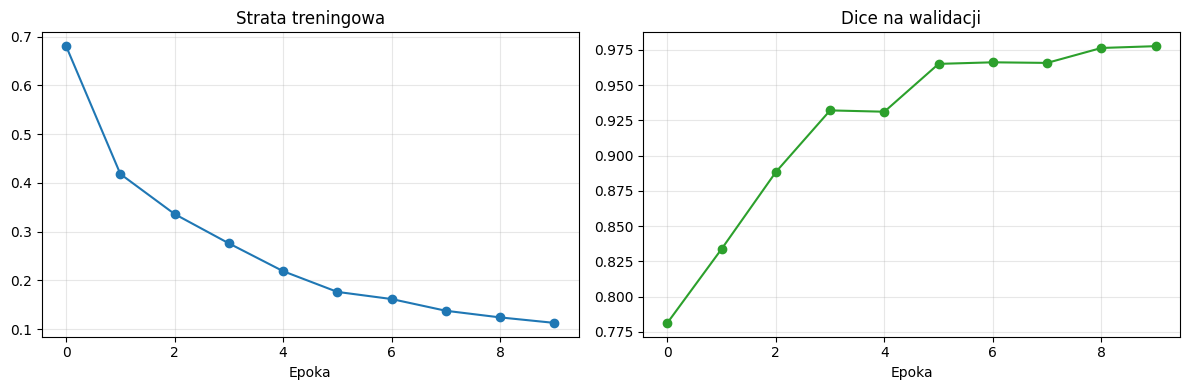

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot([entry[0] for entry in history], marker="o")
axes[0].set_title("Strata treningowa")
axes[0].set_xlabel("Epoka")
axes[0].grid(alpha=0.3)
axes[1].plot([entry[1] for entry in history], marker="o", color="tab:green")
axes[1].set_title("Dice na walidacji")
axes[1].set_xlabel("Epoka")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Test na obrazie spoza treningu

Komórka wczytuje najlepszy checkpoint i puszcza go na jednym zdjęciu z `data/test`. Ten folder nie zawiera masek referencyjnych, więc nie da się policzyć Dice - widzimy tylko predykcję sieci.

Wynik pokazany jest w trzech panelach: zdjęcie wejściowe, mapa prawdopodobieństwa i maska binarna po ustalonym progu.

`TEST_IMAGE_INDEX = None` oznacza losowe zdjęcie. Wartość liczbowa wybiera zdjęcie o danym numerze z posortowanej listy plików. Numer to pozycja na liście, a nie fragment nazwy pliku.

Obraz testowy 88697/100064: e19eee51d465_09.jpg


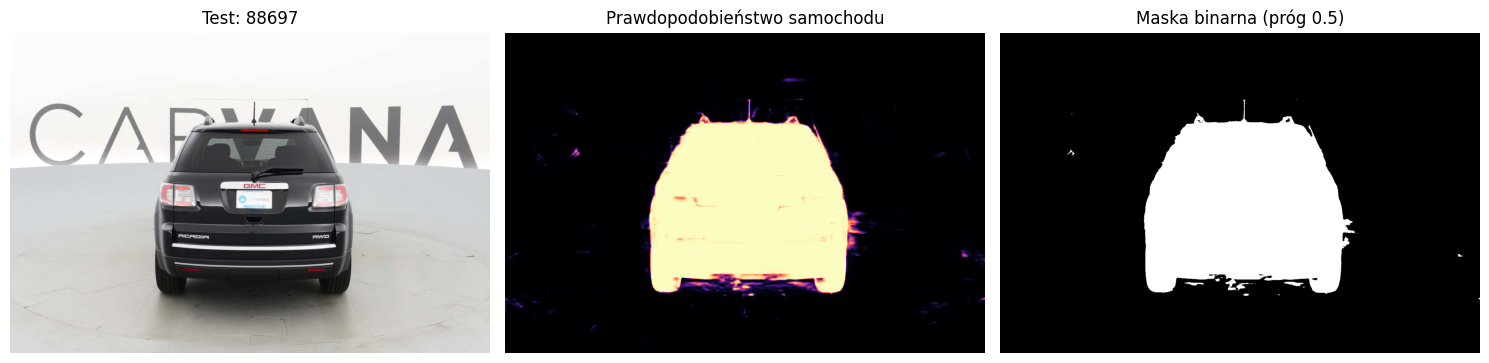

In [25]:
assert CHECKPOINT_PATH.exists(), f"Brak checkpointu w {CHECKPOINT_PATH} — uruchom komórkę treningową do końca"
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True))

test_image_paths = sorted(TEST_DIR.glob("*.jpg"))
assert test_image_paths, f"Brak obrazów testowych w {TEST_DIR}"

TEST_IMAGE_INDEX = None


def show_test_prediction(index=None):
    if index is None:
        number = random.randint(1, len(test_image_paths))
    else:
        number = index
    assert 1 <= number <= len(test_image_paths), f"Numer musi być w zakresie 1..{len(test_image_paths)}"
    image_path = test_image_paths[number - 1]
    probability = predict_full_image(model, image_path)
    prediction = probability > 0.5
    print(f"Obraz testowy {number}/{len(test_image_paths)}: {image_path.name}")

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].imshow(Image.open(image_path).convert("RGB"))
    axes[0].set_title(f"Test: {number}")
    axes[1].imshow(probability, cmap="magma")
    axes[1].set_title("Prawdopodobieństwo samochodu")
    axes[2].imshow(prediction, cmap="gray")
    axes[2].set_title("Maska binarna (próg 0.5)")
    for axis in axes:
        axis.axis("off")
    plt.tight_layout()
    plt.show()


show_test_prediction(TEST_IMAGE_INDEX)